## <2차원 데이터에서의 0차 보간>

### 기본 라이브러리 불러오기

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [19]:
P = np.array([[10.3],[15.4]])
# print(P)

Q11 = np.floor(P).astype("int16")
Q12 = Q11 + np.array([[0],[1]])
Q21 = Q11 + np.array([[1],[0]])
Q22 = Q11 + np.array([[1],[1]])
print(Q11,Q12,Q21,Q22)

[[10]
 [15]] [[10]
 [16]] [[11]
 [15]] [[11]
 [16]]


In [29]:
d1 = np.sum(np.abs(P - Q11))
d2 = np.sum(np.abs(P - Q12))
d3 = np.sum(np.abs(P - Q21))
d4 = np.sum(np.abs(P - Q22))

dist = [d1,d2,d3,d4]
print(np.argmin(dist))

if np.argmin(dist) == 0:
    Q11
elif np.argmin(dist) == 1:
    Q12
elif np.argmin(dist) == 2:
    Q21
elif np.argmin(dist) == 3:
    Q22
# print(d1,d2,d3,d4)

0


### User parameter 정의하기

In [2]:
# translation
tx, ty = 0, 0
# scaling
sx, sy = 2, 2
# rotation
theta = 0
theta_rad = theta * np.pi / 180

### 동차 행렬 생성하기

In [3]:
# Translation matrix
T = np.array([[1,0,tx],
              [0,1,ty],
              [0,0,1]])

# Scaling matrix
S = np.array([[sx,0,0],
              [0,sy,0],
              [0,0,1]])

# Rotation matrix
R = np.array([[np.cos(theta_rad), -1*np.sin(theta_rad), 0],
              [np.sin(theta_rad), np.cos(theta_rad), 0],
              [0,0,1]])

A = S
print(A)

[[2 0 0]
 [0 2 0]
 [0 0 1]]


### "triangle.jpg" 흑백 영상(f)으로 불러오고,영상의 크기(h,w)를 자동으로 구하기

In [5]:
f = cv2.imread("images/triangle.jpg",0) # gray
h,w = f.shape
print(h,w)

615 467


### 결과 데이터 (g) 생성하기

In [8]:
g = np.zeros((int(h*sx), int(w*sy)))
gh,gw = g.shape
print(gh,gw)

1230 934


### 동차 행렬, 역방향 사상을 기반으로 0차 보간 구현하기

In [11]:
g = np.zeros((int(h*sx), int(w*sy)))
gh,gw = g.shape
for x_prime in range(gh):
    for y_prime in range(gw):
        P_prime = np.array([[x_prime], [y_prime], [1]])
        P = (np.linalg.inv(A)@P_prime).astype("int16")

        if (0 <= P[0,0] < h) and (0 <= P[1,0] < w):
            g[x_prime,y_prime] = f[P[0,0],P[1,0]] 

g = g.astype("uint8")
print(g)

[[255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 ...
 [173 173  77 ...  75 177 177]
 [135 135  76 ...  74 130 130]
 [135 135  76 ...  74 130 130]]


### cv2.imshow로 시각화 하기

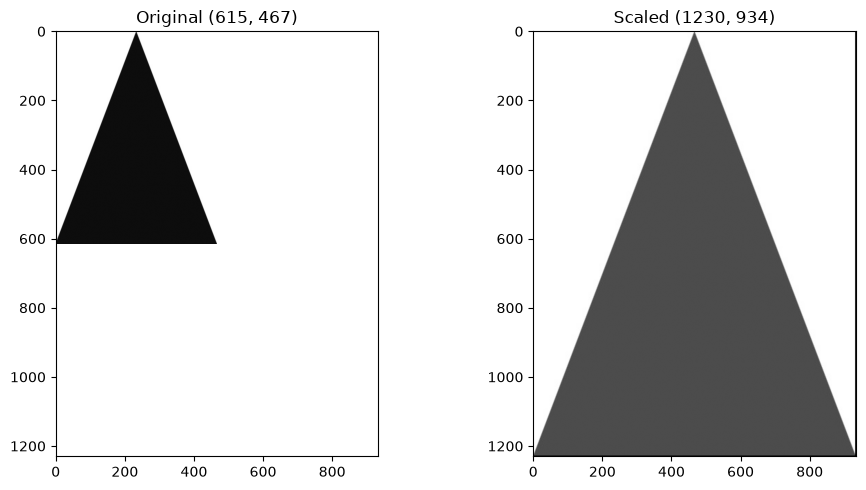

In [32]:
# cv2.imshow("f",f.astype("uint8"))
# cv2.imshow("g",g.astype("uint8"))
# cv2.waitKey(0)
# cv2.destroyAllWindows()



fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# 원본 f
axes[0].imshow(f, cmap="gray")
axes[0].set_title(f"Original {f.shape}")

# 확대된 g
axes[1].imshow(g, cmap="gray")
axes[1].set_title(f"Scaled {g.shape}")

# 두 그래프의 x, y축 최대 범위를 확대된 이미지(g) 기준으로 통일
for ax in axes:
    ax.set_xlim(0, g.shape[1])
    ax.set_ylim(g.shape[0], 0)  # 이미지는 y축이 위에서 아래로 증가하므로 반전

plt.tight_layout()
plt.show()

In [31]:
g = np.zeros((int(h*sx), int(w*sy)))
gh,gw = g.shape
for x_prime in range(gh):
    for y_prime in range(gw):
        P_prime = np.array([[x_prime], [y_prime], [1]])
        P = (np.linalg.inv(A)@P_prime) # 실수형

        # 인접한 4개 이웃
        Q11 = (np.floor(P[:2])).astype("int16")
        Q12 = Q11 + np.array([[0],[1]])
        Q21 = Q11 + np.array([[1],[0]])
        Q22 = Q11 + np.array([[1],[1]])

        # 계산하기
        d1 = np.sum(np.abs(P[:2] - Q11))
        d2 = np.sum(np.abs(P[:2] - Q12))
        d3 = np.sum(np.abs(P[:2] - Q21))
        d4 = np.sum(np.abs(P[:2] - Q22))
        dist = [d1,d2,d3,d4]

        if (0 <= Q11[0,0] and Q21[0,0] < h) and (0 <= Q11[1,0] and Q12[1,0] <w):
            if np.argmin(dist) == 0:
                g[x_prime,y_prime] = f[Q11[0,0],Q11[1,0]]
            elif np.argmin(dist) == 1:
                g[x_prime,y_prime] = f[Q12[0,0],Q12[1,0]]
            elif np.argmin(dist) == 2:
                g[x_prime,y_prime] = f[Q21[0,0],Q21[1,0]]
            elif np.argmin(dist) == 3:
                g[x_prime,y_prime] = f[Q22[0,0],Q22[1,0]]

g = g.astype("uint8")
print(g)

[[255 255 255 ... 255   0   0]
 [255 255 255 ... 255   0   0]
 [255 255 255 ... 255   0   0]
 ...
 [173 173  77 ...  75   0   0]
 [  0   0   0 ...   0   0   0]
 [  0   0   0 ...   0   0   0]]
